# DSC 411/511
# Density Estimation and DBSCAN on Ames



---
# Section 0: Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, KernelDensity
from sklearn.metrics import silhouette_score
from scipy.signal import argrelextrema

sns.set_style('whitegrid')
SEED = 0
print('ready')

ready


In [2]:
DATA_URL = 'https://jse.amstat.org/v19n3/decock/AmesHousing.txt'
df = pd.read_csv(DATA_URL, sep='\t')       # tab separated
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 2930
Columns: 82


In [3]:
# Same eight columns as last class, so the comparison is fair
FEATURES = [
    'Gr Liv Area', 'Lot Area', 'Overall Qual', 'Year Built',
    'Total Bsmt SF', 'Garage Area', 'TotRms AbvGrd', 'Full Bath',
]

work = df[FEATURES + ['SalePrice', 'Neighborhood']].copy()
work[FEATURES] = work[FEATURES].fillna(work[FEATURES].median())

X  = work[FEATURES]
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)

print(f'{X.shape[0]:,} houses, {X.shape[1]} columns, standardized')

2,930 houses, 8 columns, standardized


---
# Section 1: Is There a Gap in the Price?

The fish had an obvious gap: nothing between 12 kg and 50 kg. That gap is what made
two clusters obvious.

**Does SalePrice have a gap?**

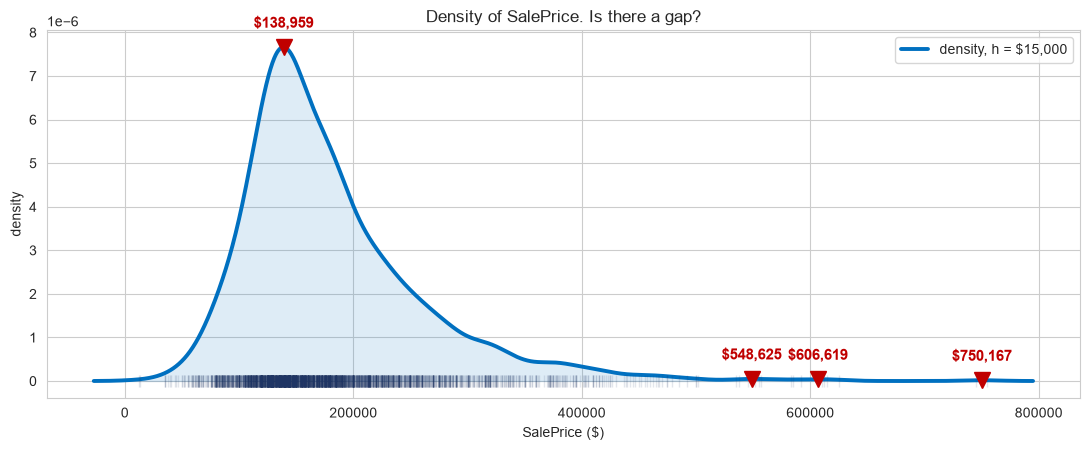

Peaks found   : 4   at $138,959, $548,625, $606,619, $750,167
Valleys found : 3

More than one peak. The valleys between them are natural cut points.


In [4]:
def kde1d(x, data, h):
    """Our own KDE, so nothing is hidden. h is in the units of the data."""
    data = np.asarray(data, float)
    x = np.atleast_1d(np.asarray(x, float))
    return np.mean(np.exp(-0.5 * ((x[:, None] - data) / h) ** 2)
                   / (h * np.sqrt(2 * np.pi)), axis=1)

price = work['SalePrice'].values
h_price = 15000                                  # 15,000 dollars
grid = np.linspace(price.min() - 40000, price.max() + 40000, 2000)
dens = kde1d(grid, price, h_price)

peaks = argrelextrema(dens, np.greater)[0]
valleys = argrelextrema(dens, np.less)[0]

plt.figure(figsize=(11, 4.6))
plt.plot(grid, dens, color='#0070C0', lw=2.8, label=f'density, h = ${h_price:,}')
plt.fill_between(grid, dens, alpha=.13, color='#0070C0')
plt.plot(price, np.zeros(len(price)), '|', ms=8, alpha=.12, color='#1F3564')
for p in peaks:
    plt.plot(grid[p], dens[p], 'v', ms=12, color='#C00000', zorder=8)
    plt.annotate(f'${grid[p]:,.0f}', (grid[p], dens[p]), textcoords='offset points',
                 xytext=(0, 14), ha='center', fontsize=11, fontweight='bold', color='#C00000')
plt.xlabel('SalePrice ($)'); plt.ylabel('density')
plt.title('Density of SalePrice. Is there a gap?')
plt.legend(); plt.tight_layout(); plt.show()

print(f'Peaks found   : {len(peaks)}   at ' +
      ', '.join(f'${grid[p]:,.0f}' for p in peaks))
print(f'Valleys found : {len(valleys)}')
print()
if len(peaks) == 1:
    print('ONE peak. No gap. Prices form a continuum, not separate groups.')
    print('That is why k-means gave a low silhouette last week. There was nothing to separate.')
else:
    print('More than one peak. The valleys between them are natural cut points.')

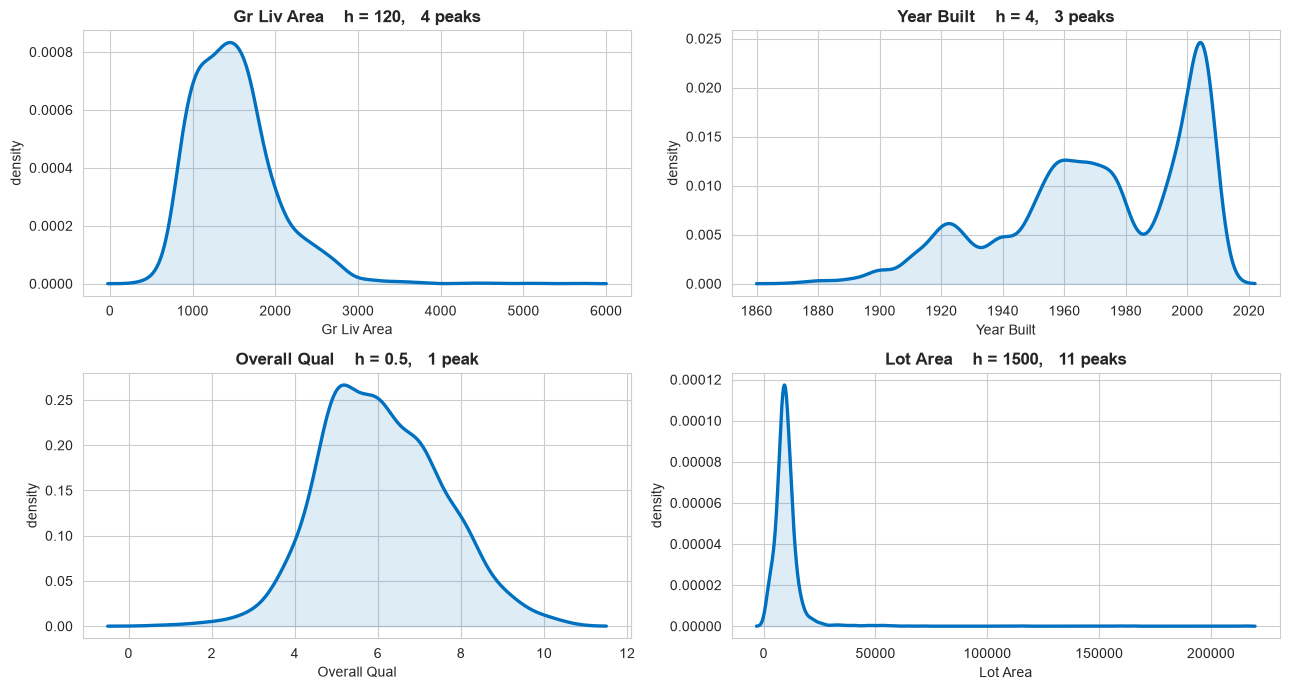

A column with one peak has no natural groups inside it.
A column with two clear peaks and a valley between them does.


In [5]:
# The same question for three other columns
COLS_1D = ['Gr Liv Area', 'Year Built', 'Overall Qual', 'Lot Area']
BW      = {'Gr Liv Area': 120, 'Year Built': 4, 'Overall Qual': 0.5, 'Lot Area': 1500}

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, c in zip(axes.ravel(), COLS_1D):
    v = work[c].values
    gg = np.linspace(v.min() - 3*BW[c], v.max() + 3*BW[c], 1200)
    dd = kde1d(gg, v, BW[c])
    npk = len(argrelextrema(dd, np.greater)[0])
    ax.plot(gg, dd, color='#0070C0', lw=2.4)
    ax.fill_between(gg, dd, alpha=.13, color='#0070C0')
    ax.set_title(f'{c}    h = {BW[c]},   {npk} peak{"s" if npk != 1 else ""}',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel(c); ax.set_ylabel('density')
plt.tight_layout(); plt.show()

print('A column with one peak has no natural groups inside it.')
print('A column with two clear peaks and a valley between them does.')

---
# Section 2: Bandwidth, on Real Data

Same six-panel experiment as the fish, now on 2,930 house prices.

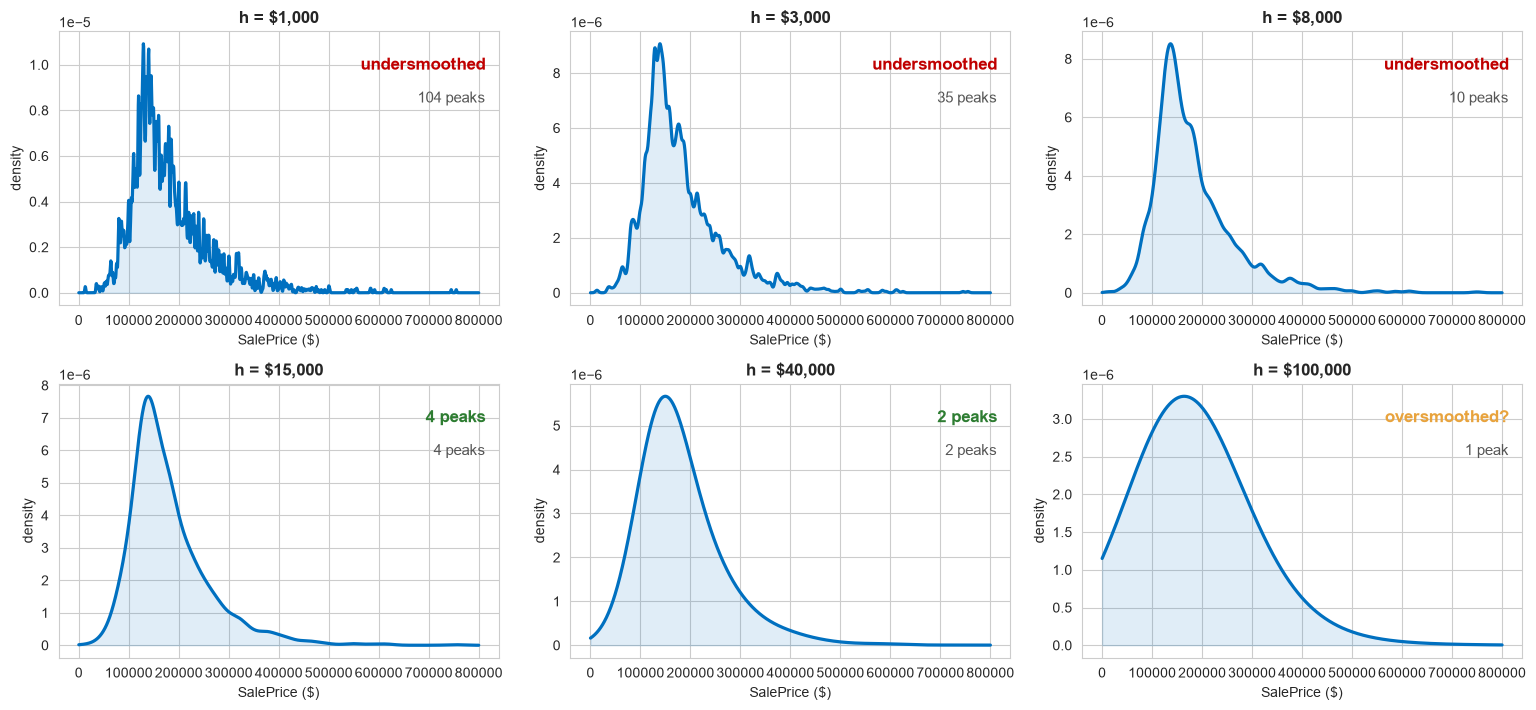

         h   peaks   what you would report
$    1,000     104   every price band is a group
$    3,000      35   every price band is a group
$    8,000      10   every price band is a group
$   15,000       4   4 price groups
$   40,000       2   2 price groups
$  100,000       1   one continuous market

Same 2,930 houses. The number of groups you would report depends
entirely on a number you chose.


In [6]:
H_PANEL = [1000, 3000, 8000, 15000, 40000, 100000]

fig, axes = plt.subplots(2, 3, figsize=(15.5, 7.2))
for ax, h in zip(axes.ravel(), H_PANEL):
    gg = np.linspace(0, 800000, 1500)
    dd = kde1d(gg, price, h)
    npk = len(argrelextrema(dd, np.greater)[0])
    if npk > 4:    verdict, col = 'undersmoothed', '#C00000'
    elif npk == 1: verdict, col = 'oversmoothed?', '#E8A33D'
    else:          verdict, col = f'{npk} peaks', '#2E7D32'
    ax.plot(gg, dd, color='#0070C0', lw=2.3)
    ax.fill_between(gg, dd, alpha=.12, color='#0070C0')
    ax.set_title(f'h = ${h:,}', fontsize=12.5, fontweight='bold')
    ax.text(.97, .86, verdict, transform=ax.transAxes, ha='right',
            fontsize=12, fontweight='bold', color=col)
    ax.text(.97, .74, f'{npk} peak{"s" if npk != 1 else ""}',
            transform=ax.transAxes, ha='right', fontsize=10.5, color='#555555')
    ax.set_xlabel('SalePrice ($)'); ax.set_ylabel('density')
plt.tight_layout(); plt.show()

print(f"{'h':>10}{'peaks':>8}   what you would report")
for h in H_PANEL:
    gg = np.linspace(0, 800000, 1500)
    npk = len(argrelextrema(kde1d(gg, price, h), np.greater)[0])
    msg = ('every price band is a group' if npk > 4 else
           'one continuous market' if npk == 1 else f'{npk} price groups')
    print(f'${h:>9,}{npk:>8}   {msg}')
print()
print('Same 2,930 houses. The number of groups you would report depends')
print('entirely on a number you chose.')

---
# Section 3: Density in 2D, and Why k-means Struggled

Last week's cluster plot showed four colours with no gaps between them. Now put a
density estimate underneath it.

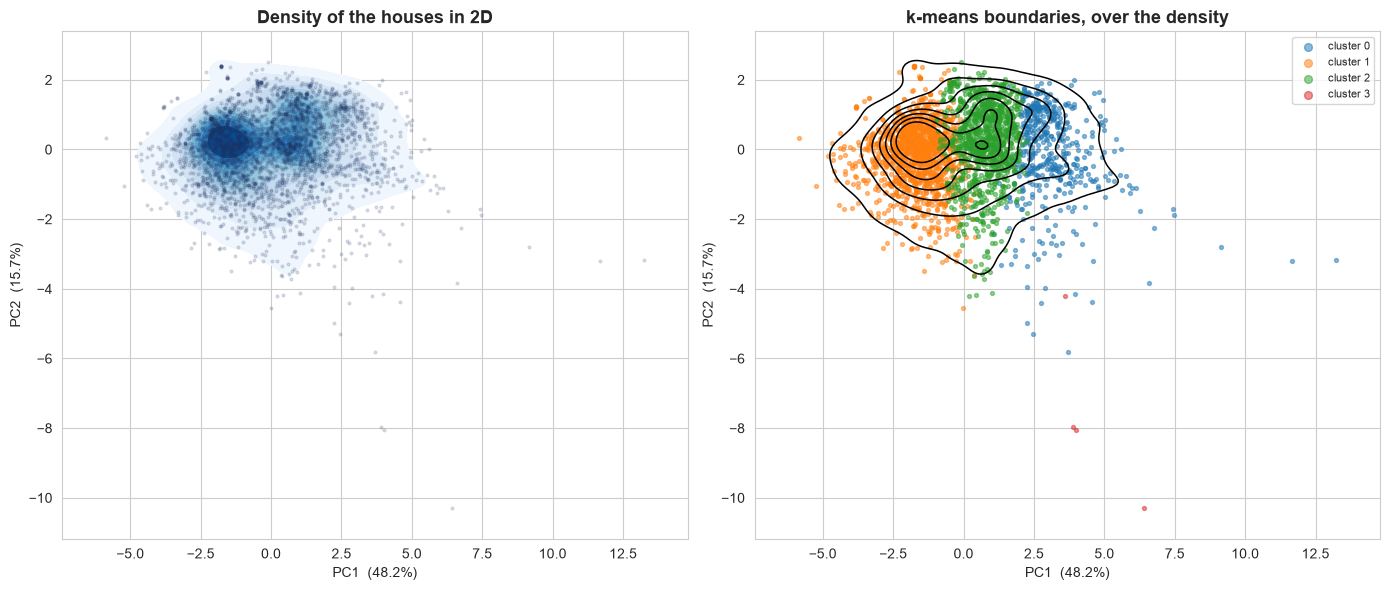

Left: ONE hill. One dense core, tails falling away in every direction.
Right: four clusters cut straight through that single hill.

k-means did not find four groups. It cut one group into four slices.
Silhouette at k=4: 0.2610


In [7]:
p2 = PCA(n_components=2).fit(Xs)
Z2 = p2.transform(Xs)

km = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(Xs)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.kdeplot(x=Z2[:, 0], y=Z2[:, 1], fill=True, levels=12, cmap='Blues', ax=ax[0])
ax[0].scatter(Z2[:, 0], Z2[:, 1], s=4, alpha=.15, color='#1F3564')
ax[0].set_title('Density of the houses in 2D', fontsize=13, fontweight='bold')

for c in range(4):
    m = km.labels_ == c
    ax[1].scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=.5, label=f'cluster {c}')
sns.kdeplot(x=Z2[:, 0], y=Z2[:, 1], levels=8, color='black',
            linewidths=1.1, ax=ax[1])
ax[1].set_title('k-means boundaries, over the density', fontsize=13, fontweight='bold')
ax[1].legend(fontsize=8, markerscale=2)

for a_ in ax:
    a_.set_xlabel(f'PC1  ({p2.explained_variance_ratio_[0]*100:.1f}%)')
    a_.set_ylabel(f'PC2  ({p2.explained_variance_ratio_[1]*100:.1f}%)')
plt.tight_layout(); plt.show()

print('Left: ONE hill. One dense core, tails falling away in every direction.')
print('Right: four clusters cut straight through that single hill.')
print()
print('k-means did not find four groups. It cut one group into four slices.')
print(f'Silhouette at k=4: {silhouette_score(Xs, km.labels_):.4f}')

---
# Section 4: Density as an Outlier Score

Low density means: not many houses near this one.

In [8]:
kd = KernelDensity(kernel='gaussian', bandwidth=0.7).fit(Xs)
logdens = kd.score_samples(Xs)          # log density for every house
work['logdens'] = logdens

print('Density (log scale) across all houses:')
print(pd.Series(logdens).describe().round(2).to_string())
print()
print('THE 8 HOUSES IN THE EMPTIEST REGIONS')
odd = work.nsmallest(8, 'logdens')
print(odd[['Gr Liv Area', 'Lot Area', 'Overall Qual', 'Year Built',
           'SalePrice', 'logdens']].round(1).to_string())

Density (log scale) across all houses:
count    2930.00
mean       -8.98
std         1.30
min       -12.48
25%        -9.72
50%        -8.64
75%        -8.00
max        -7.13

THE 8 HOUSES IN THE EMPTIEST REGIONS
      Gr Liv Area  Lot Area  Overall Qual  Year Built  SalePrice  logdens
956          2036    215245             7        1965     375000    -12.5
2071         1824    115149             7        1971     302000    -12.5
1498         5642     63887            10        2008     160000    -12.5
2180         5095     39290            10        2008     183850    -12.5
1497         3820     47007             5        1959     284700    -12.5
2278         2034     43500             3        1953     130000    -12.5
2522         1842     50271             9        1981     385000    -12.5
1406         2358     45600             6        1908     240000    -12.5


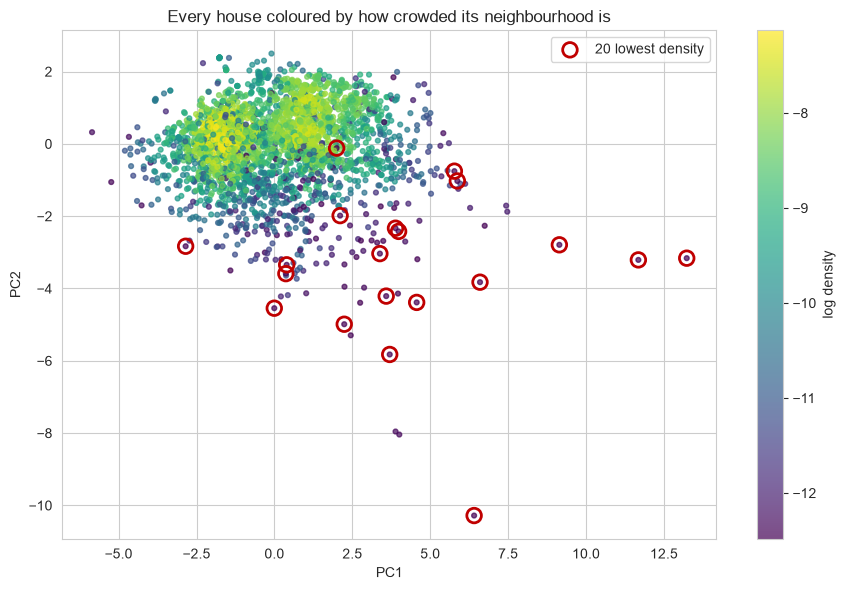

Dark points sit in empty regions. They are unusual houses, by definition.
No labels were needed to find them. That is anomaly detection, and it is Oct 28.


In [9]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=logdens, s=12, cmap='viridis', alpha=.7)
plt.colorbar(sc, label='log density')
low = work['logdens'].nsmallest(20).index
pos = work.index.get_indexer(low)
plt.scatter(Z2[pos, 0], Z2[pos, 1], s=110, facecolors='none',
            edgecolors='#C00000', linewidths=2, label='20 lowest density')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Every house coloured by how crowded its neighbourhood is')
plt.legend(); plt.tight_layout(); plt.show()

print('Dark points sit in empty regions. They are unusual houses, by definition.')
print('No labels were needed to find them. That is anomaly detection, and it is Oct 28.')

---
# Section 5: DBSCAN, Core, Border and Noise

DBSCAN uses the crudest density estimate there is: draw a circle of radius `eps`
and count what is inside.

| Term | Meaning |
|---|---|
| **Core point** | At least `min_samples` points within `eps`, including itself |
| **Border point** | Fewer than that, but inside some core point's circle |
| **Noise** | Neither. Belongs to no cluster at all |

In [10]:
# A tiny 2D example first, so the three labels are visible
toy = np.array([
    [1,1],[1.4,1.2],[0.8,1.5],[1.2,0.7],[1.6,1.6],   # a dense blob
    [5,5],[5.3,5.2],[4.8,5.4],[5.1,4.7],             # another dense blob
    [3.0,3.0],                                        # in the middle, alone
    [8.5,1.0],                                        # far away
])
EPS_T, MIN_T = 0.9, 3

db_t = DBSCAN(eps=EPS_T, min_samples=MIN_T).fit(toy)
nn_t = NearestNeighbors(radius=EPS_T).fit(toy)
counts_t = np.array([len(a) for a in nn_t.radius_neighbors(toy, return_distance=False)]) + 1

core_mask = np.zeros(len(toy), bool)
core_mask[db_t.core_sample_indices_] = True

print(f'eps = {EPS_T},  min_samples = {MIN_T}')
print()
print(f"{'point':>16}{'neighbours':>13}{'label':>10}{'type':>10}")
for i, (p, n, l) in enumerate(zip(toy, counts_t, db_t.labels_)):
    if l == -1:            t = 'NOISE'
    elif core_mask[i]:     t = 'core'
    else:                  t = 'border'
    lab = 'noise' if l == -1 else f'cluster {l}'
    print(f'  ({p[0]:>4.1f},{p[1]:>4.1f}){n:>13}{lab:>12}{t:>10}')

eps = 0.9,  min_samples = 3

           point   neighbours     label      type
  ( 1.0, 1.0)            6   cluster 0      core
  ( 1.4, 1.2)            6   cluster 0      core
  ( 0.8, 1.5)            6   cluster 0      core
  ( 1.2, 0.7)            5   cluster 0      core
  ( 1.6, 1.6)            5   cluster 0      core
  ( 5.0, 5.0)            5   cluster 1      core
  ( 5.3, 5.2)            5   cluster 1      core
  ( 4.8, 5.4)            5   cluster 1      core
  ( 5.1, 4.7)            5   cluster 1      core
  ( 3.0, 3.0)            2       noise     NOISE
  ( 8.5, 1.0)            2       noise     NOISE


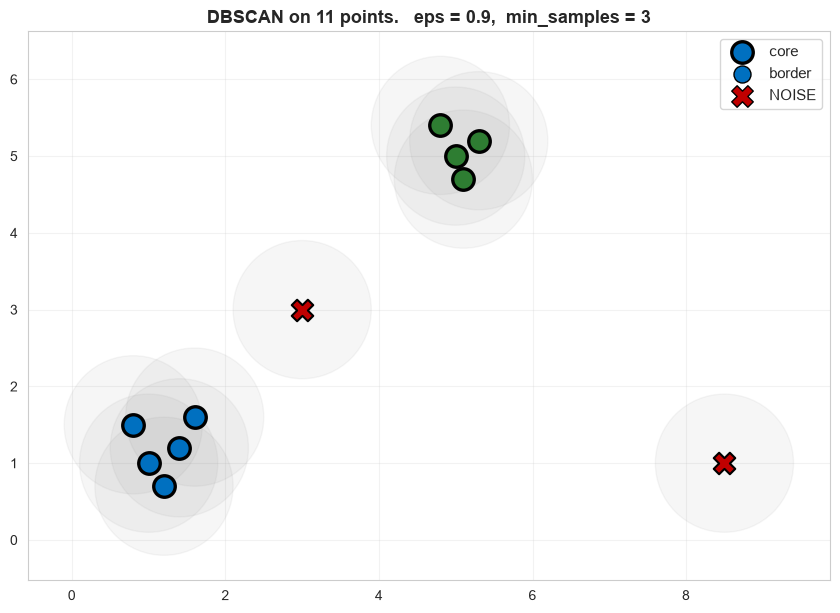

DBSCAN found 2 clusters and called 2 point(s) noise.
Nobody told it how many clusters to look for.


In [11]:
plt.figure(figsize=(8.5, 6.5))
COLS = ['#0070C0', '#2E7D32', '#6A1B9A']
for i, (p, l) in enumerate(zip(toy, db_t.labels_)):
    if l == -1:
        plt.scatter(*p, c='#C00000', s=240, marker='X', edgecolors='black',
                    linewidths=1.5, zorder=6)
    else:
        col = COLS[l % len(COLS)]
        plt.scatter(*p, c=col, s=240 if core_mask[i] else 150,
                    edgecolors='black', linewidths=2.4 if core_mask[i] else 1,
                    zorder=6)
    plt.gca().add_patch(plt.Circle(p, EPS_T, color='grey', alpha=.07, zorder=1))

plt.scatter([], [], c='#0070C0', s=240, edgecolors='black', linewidths=2.4, label='core')
plt.scatter([], [], c='#0070C0', s=150, edgecolors='black', label='border')
plt.scatter([], [], c='#C00000', s=240, marker='X', edgecolors='black', label='NOISE')
plt.gca().set_aspect('equal'); plt.grid(alpha=.25)
plt.title(f'DBSCAN on 11 points.   eps = {EPS_T},  min_samples = {MIN_T}',
          fontsize=13, fontweight='bold')
plt.legend(fontsize=11); plt.tight_layout(); plt.show()

n_noise = int((db_t.labels_ == -1).sum())
n_clust = len(set(db_t.labels_)) - (1 if -1 in db_t.labels_ else 0)
print(f'DBSCAN found {n_clust} clusters and called {n_noise} point(s) noise.')
print('Nobody told it how many clusters to look for.')

---
# Section 6: Choosing eps

You traded away k. In return you now have to choose `eps`, and it is harder.

The standard tool: sort every point by its distance to its k-th nearest neighbour,
and look for the elbow.

min_samples = 16   (2 x 8 columns)


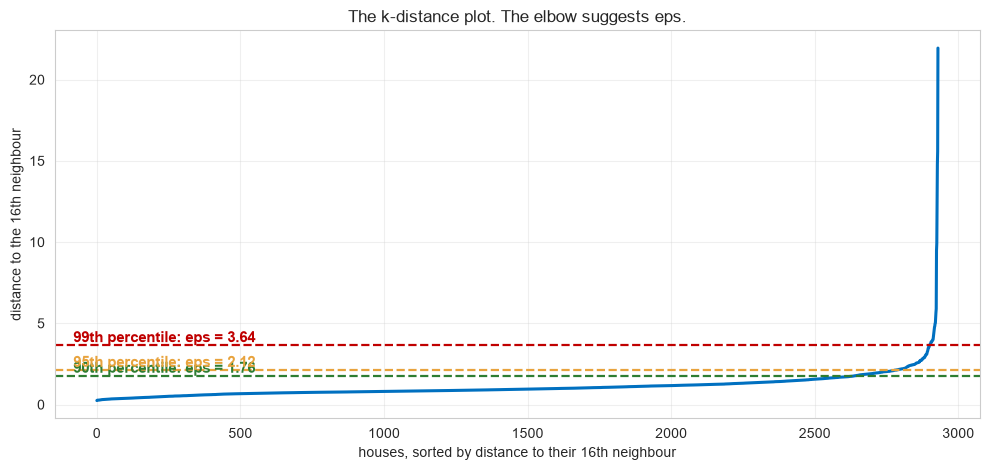

Read it left to right. Most houses have close neighbours, so the line is flat.
Where it turns sharply upward, those houses are getting isolated.
Put eps near that turn.


In [12]:
MIN_SAMPLES = 2 * Xs.shape[1]          # a common rule: 2 x number of columns
print(f'min_samples = {MIN_SAMPLES}   (2 x {Xs.shape[1]} columns)')

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs)
dist, _ = nn.kneighbors(Xs)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(10, 4.8))
plt.plot(kdist, lw=2.2, color='#0070C0')
for q, col in [(90, '#2E7D32'), (95, '#E8A33D'), (99, '#C00000')]:
    v = np.percentile(kdist, q)
    plt.axhline(v, color=col, ls='--', lw=1.6)
    plt.annotate(f'{q}th percentile: eps = {v:.2f}', (0.02, v),
                 xycoords=('axes fraction', 'data'), va='bottom',
                 fontsize=11, fontweight='bold', color=col)
plt.xlabel(f'houses, sorted by distance to their {MIN_SAMPLES}th neighbour')
plt.ylabel(f'distance to the {MIN_SAMPLES}th neighbour')
plt.title('The k-distance plot. The elbow suggests eps.')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print('Read it left to right. Most houses have close neighbours, so the line is flat.')
print('Where it turns sharply upward, those houses are getting isolated.')
print('Put eps near that turn.')

---
# Section 7: DBSCAN on Ames

In [13]:
rows = []
for eps in [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xs)
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    n_n = int((lab == -1).sum())
    biggest = 0 if n_c == 0 else max(np.sum(lab == c) for c in set(lab) if c != -1)
    rows.append({'eps': eps, 'clusters': n_c, 'noise': n_n,
                 'noise %': round(n_n / len(lab) * 100, 1),
                 'biggest cluster': biggest})
sweep = pd.DataFrame(rows)
print(f'min_samples = {MIN_SAMPLES}')
print()
print(sweep.to_string(index=False))
print()
print('Watch what happens as eps grows:')
print('  small eps -> almost everything is noise')
print('  large eps -> one giant cluster swallows everything')
print('  in between -> is there anything in between?')

min_samples = 16

 eps  clusters  noise  noise %  biggest cluster
 0.5         8   2488     84.9              114
 0.8         4   1324     45.2              681
 1.0         2    825     28.2             1124
 1.2         2    447     15.3             1294
 1.5         2    232      7.9             1426
 2.0         1     69      2.4             2861
 2.5         1     38      1.3             2892
 3.0         1     19      0.6             2911

Watch what happens as eps grows:
  small eps -> almost everything is noise
  large eps -> one giant cluster swallows everything
  in between -> is there anything in between?


In [14]:
EPS = 1.2          # change this after reading the table above

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xs)
work['dbscan'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = int((db.labels_ == -1).sum())

print(f'eps = {EPS},  min_samples = {MIN_SAMPLES}')
print(f'   clusters found : {n_clusters}')
print(f'   noise points   : {n_noise:,}  ({n_noise/len(work)*100:.1f}%)')
print()
for c in sorted(set(db.labels_)):
    n = int((db.labels_ == c).sum())
    name = 'NOISE' if c == -1 else f'cluster {c}'
    print(f'   {name:<12} {n:>6,} houses  ({n/len(work)*100:>5.1f}%)')

eps = 1.2,  min_samples = 16
   clusters found : 2
   noise points   : 447  (15.3%)

   NOISE           447 houses  ( 15.3%)
   cluster 0     1,189 houses  ( 40.6%)
   cluster 1     1,294 houses  ( 44.2%)


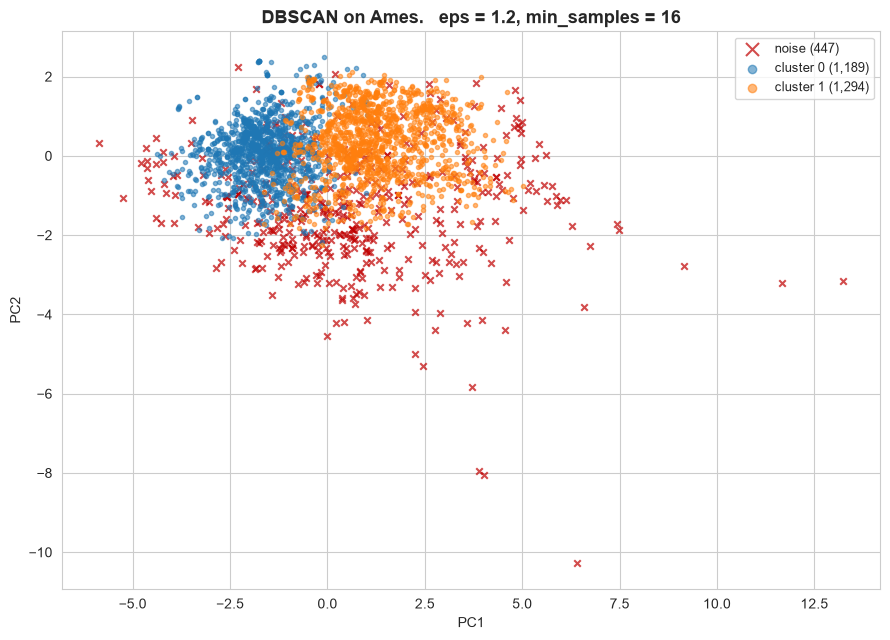

In [15]:
plt.figure(figsize=(9, 6.5))
noise = db.labels_ == -1
plt.scatter(Z2[noise, 0], Z2[noise, 1], c='#C00000', s=22, marker='x',
            alpha=.7, label=f'noise ({noise.sum():,})')
for c in sorted(set(db.labels_) - {-1}):
    m = db.labels_ == c
    plt.scatter(Z2[m, 0], Z2[m, 1], s=9, alpha=.55,
                label=f'cluster {c} ({m.sum():,})')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'DBSCAN on Ames.   eps = {EPS}, min_samples = {MIN_SAMPLES}',
          fontsize=13, fontweight='bold')
plt.legend(fontsize=9, markerscale=2); plt.tight_layout(); plt.show()

In [16]:
# What are the noise houses actually like?
if n_noise > 0:
    print('THE HOUSES DBSCAN REFUSED TO CLUSTER')
    print()
    comp = pd.DataFrame({
        'noise houses': work[noise][FEATURES + ['SalePrice']].mean(),
        'everyone else': work[~noise][FEATURES + ['SalePrice']].mean(),
    }).round(0)
    comp['ratio'] = (comp['noise houses'] / comp['everyone else']).round(2)
    print(comp.to_string())
    print()
    print('If the noise houses are genuinely bigger, older or more expensive,')
    print('DBSCAN found something real. If they look average, eps is wrong.')
else:
    print('No noise at this eps. Lower it and try again.')

THE HOUSES DBSCAN REFUSED TO CLUSTER

               noise houses  everyone else  ratio
Gr Liv Area          1907.0         1426.0   1.34
Lot Area            15380.0         9206.0   1.67
Overall Qual            6.0            6.0   1.00
Year Built           1954.0         1974.0   0.99
Total Bsmt SF        1043.0         1053.0   0.99
Garage Area           491.0          469.0   1.05
TotRms AbvGrd           8.0            6.0   1.33
Full Bath               2.0            2.0   1.00
SalePrice          199783.0       177378.0   1.13

If the noise houses are genuinely bigger, older or more expensive,
DBSCAN found something real. If they look average, eps is wrong.


### The honest reading

On Ames, DBSCAN tends to give you one of two useless answers:

- **One huge cluster plus scattered noise.** Because the data is one dense hill.
- **Everything is noise.** Because eps was too small for 8 dimensions.

That is not a bug. It is DBSCAN telling you the truth: **there are no dense regions
separated by sparse ones.** k-means and hierarchical could not tell you that, because
they are obliged to produce clusters no matter what.

**A method that can fail is more informative than one that cannot.**

---
# Section 8: Where DBSCAN Wins

Ames is the wrong shape for it. Here is the right shape.

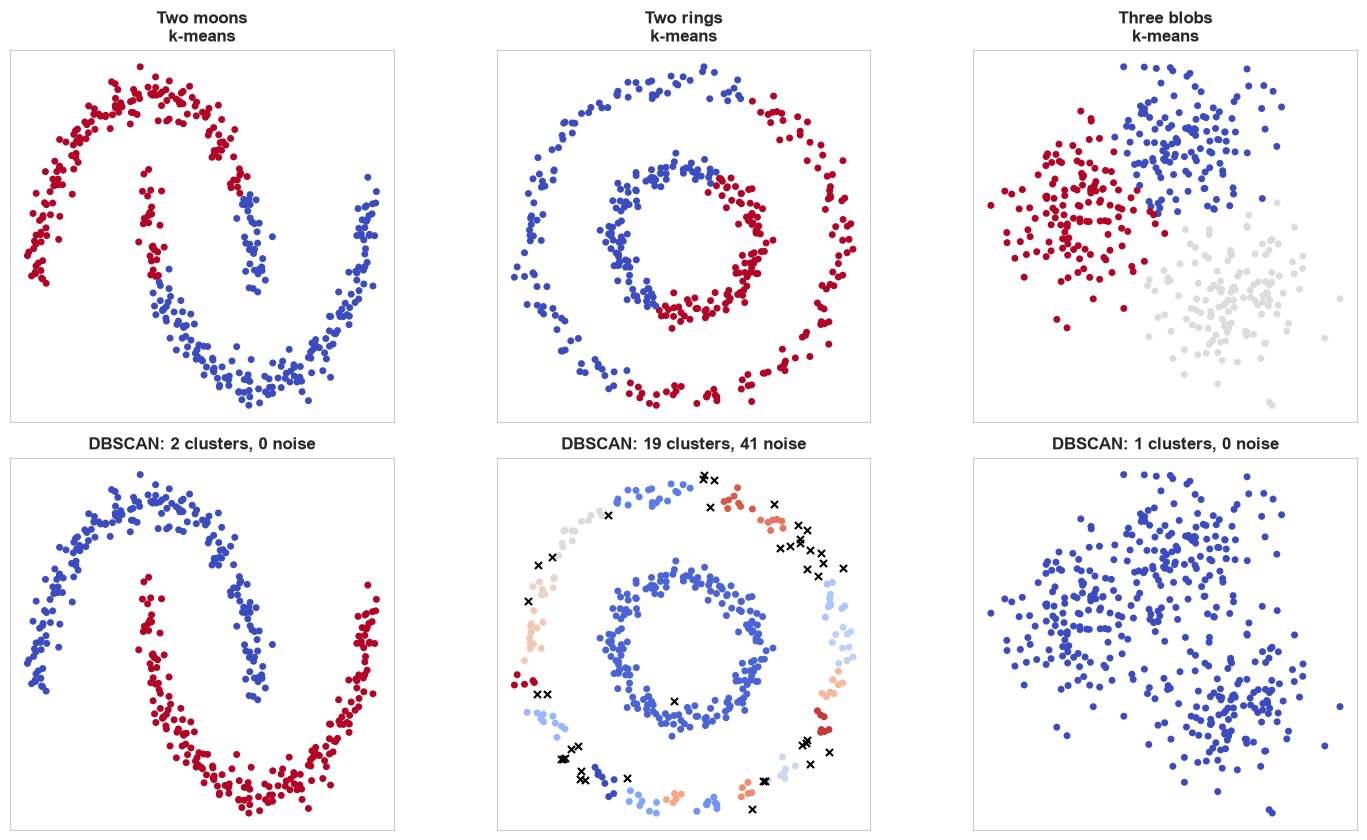

Top row: k-means. It can only draw straight boundaries between centroids.
Bottom row: DBSCAN follows the shape, whatever the shape is.

On the blobs they agree. On the moons and rings, only one of them is right.


In [17]:
from sklearn.datasets import make_moons, make_circles, make_blobs

datasets = {
    'Two moons':  make_moons(n_samples=400, noise=0.06, random_state=SEED)[0],
    'Two rings':  make_circles(n_samples=400, noise=0.05, factor=0.45, random_state=SEED)[0],
    'Three blobs': make_blobs(n_samples=400, centers=3, cluster_std=0.9, random_state=SEED)[0],
}
PARAMS = {'Two moons': 0.22, 'Two rings': 0.16, 'Three blobs': 0.9}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for j, (name, D) in enumerate(datasets.items()):
    Ds = StandardScaler().fit_transform(D)
    k = 3 if name == 'Three blobs' else 2

    km_l = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Ds)
    db_l = DBSCAN(eps=PARAMS[name], min_samples=5).fit_predict(Ds)

    axes[0, j].scatter(Ds[:, 0], Ds[:, 1], c=km_l, cmap='coolwarm', s=16)
    axes[0, j].set_title(f'{name}\nk-means', fontsize=12, fontweight='bold')

    nz = db_l == -1
    axes[1, j].scatter(Ds[~nz, 0], Ds[~nz, 1], c=db_l[~nz], cmap='coolwarm', s=16)
    axes[1, j].scatter(Ds[nz, 0], Ds[nz, 1], c='black', marker='x', s=26)
    nc = len(set(db_l)) - (1 if -1 in db_l else 0)
    axes[1, j].set_title(f'DBSCAN: {nc} clusters, {nz.sum()} noise',
                         fontsize=12, fontweight='bold')

    for a_ in (axes[0, j], axes[1, j]):
        a_.set_aspect('equal'); a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

print('Top row: k-means. It can only draw straight boundaries between centroids.')
print('Bottom row: DBSCAN follows the shape, whatever the shape is.')
print()
print('On the blobs they agree. On the moons and rings, only one of them is right.')

---
# Section 9: Three Methods, One Dataset

In [18]:
hc = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(Xs)

summary = []
for name, lab in [('k-means (k=4)', km.labels_),
                  ('Hierarchical, ward (k=4)', hc.labels_),
                  (f'DBSCAN (eps={EPS})', db.labels_)]:
    nz = lab == -1
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    # silhouette needs 2+ clusters among the non-noise points
    if n_c >= 2 and (~nz).sum() > n_c:
        s = silhouette_score(Xs[~nz], lab[~nz])
    else:
        s = np.nan
    summary.append({'method': name,
                    'clusters': n_c,
                    'noise': int(nz.sum()),
                    'silhouette': round(s, 4) if s == s else 'n/a'})
print(pd.DataFrame(summary).to_string(index=False))
print()
print('Only one of these three was allowed to say "I found nothing."')

                  method  clusters  noise  silhouette
           k-means (k=4)         4      0      0.2610
Hierarchical, ward (k=4)         4      0      0.2251
        DBSCAN (eps=1.2)         2    447      0.3618

Only one of these three was allowed to say "I found nothing."
